
#<h1><font color="#7D3C98">***Tarea 2: Modelos de regresión en Python***</font></h1>


**Universidad Industrial de Santander**  
**Escuela de Matemáticas**  
**Asignatura:** Estadística II  
**Profesor:** Andrés Ríos Gutiérrez

#<h1><font color="#5DADE2">***INTEGRANTES***</font></h1>

1. Javier M. Castellanos Hurtado 2212517
2. Sergio Andrés Gonzalez Hoya 2231440
3. Manuel F. Guerrero León 2220953
4. Valentina Ríos Osorio 2242815

***Fecha de entrega:*** 23 de octubre de 2026.

#<h1><font color="#D97706">***OBJETIVOS***</font></h1>
 <h1><font color="#17365D">Analizar de manera integral la relación estadística entre el índice socioeconómico individual de los estudiantes y su desempeño en las pruebas Saber 11, mediante técnicas de análisis exploratorio, visualización de datos, medidas de correlación y modelos de regresión implementados en Python, con el propósito de identificar patrones de asociación, evaluar la capacidad explicativa y predictiva de los puntajes en las distintas áreas del conocimiento, comparar el desempeño de los modelos de regresión lineal múltiple y redes neuronales, y reconocer sus alcances y limitaciones en la estimación de valores faltantes y el análisis de perfiles académicos hipotéticos.</font></h1>



#<h1><font color="#7D3C98">***INTRODUCCIÓN***</font></h1>

El análisis estadístico de los resultados de las pruebas Saber 11 permite explorar las relaciones entre el desempeño académico de los estudiantes y diferentes características asociadas a su contexto socioeconómico. En este trabajo se estudia la relación entre el índice socioeconómico individual (ESTU_INSE_INDIVIDUAL) y los puntajes obtenidos en las áreas de lectura crítica, matemáticas, ciencias naturales, sociales y ciudadanas e inglés, mediante herramientas de análisis de datos y aprendizaje automático implementadas en Python.

Para desarrollar el análisis, se realizó una limpieza inicial de los datos, se elaboraron diagramas de dispersión y se calcularon los coeficientes de correlación de Pearson, Spearman y Kendall, con el propósito de identificar y comparar las asociaciones entre las variables. Posteriormente, se evaluó la capacidad explicativa de los puntajes mediante modelos de regresión lineal múltiple, utilizando el coeficiente de determinación \(R^2\) para examinar la contribución de cada variable explicativa. También se construyó una representación gráfica tridimensional para observar conjuntamente la relación entre el índice socioeconómico y dos áreas del conocimiento.

Finalmente, se comparó el desempeño de un modelo de regresión lineal múltiple con el de una red neuronal artificial tipo perceptrón multicapa (MLP), utilizando datos de entrenamiento y prueba. Asimismo, se empleó el modelo con mejor desempeño para estimar los valores faltantes del índice socioeconómico en los registros que contaban con información completa de las variables explicativas, y se analizaron perfiles académicos hipotéticos relacionados con programas universitarios de interés. De esta manera, el trabajo busca comprender los patrones presentes en los datos, evaluar las posibilidades predictivas de los modelos y reconocer sus limitaciones.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()
import pandas as pd
import io
datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']),
delimiter='¬')

Saving SB11_20231.TXT to SB11_20231.TXT


/tmp/ipykernel_588/1407203924.py:5: ParserWarning: Falling back to the 'python' engine because the separator encoded in utf-8 is > 1 char long, and the 'c' engine does not support such separators; you can avoid this warning by specifying engine='python'.
  datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']),


In [ ]:
icfes_sin_nan = datos_icfes[
    (~datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
    (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
    (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
    (~datos_icfes['PUNT_C_NATURALES'].isna()) &
    (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
    (~datos_icfes['PUNT_INGLES'].isna())
]


#<h1><font color="#7D3C98">***Selección de variables explicativas mediante diagramas de dispersión***</font></h1>

Se elaboran diagramas de dispersión para estudiar la relación entre la variable respuesta, `ESTU_INSE_INDIVIDUAL`, y cada una de las cinco variables explicativas correspondientes a los puntajes de las pruebas Saber 11.

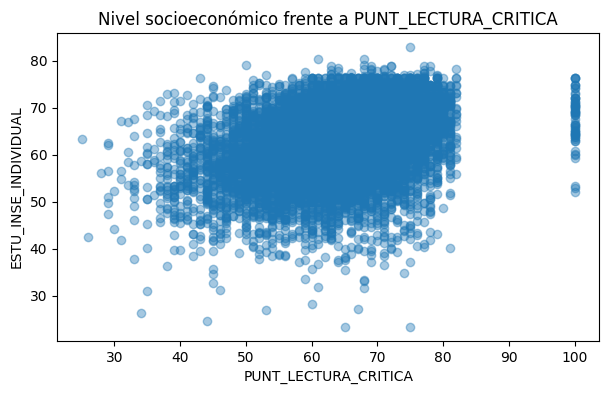

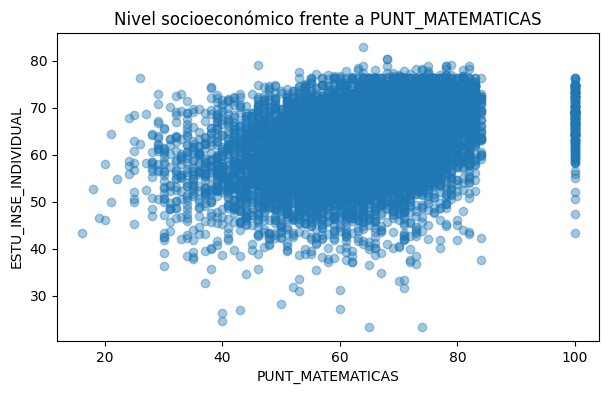

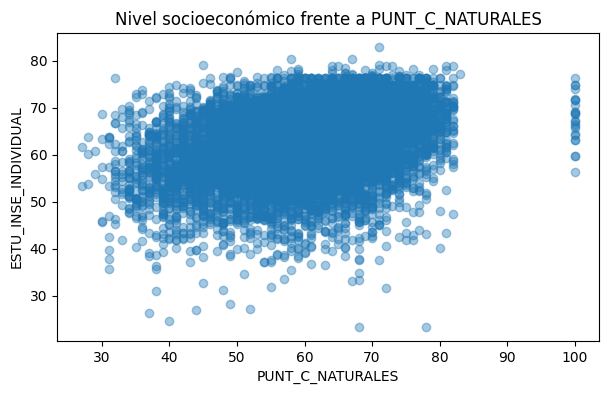

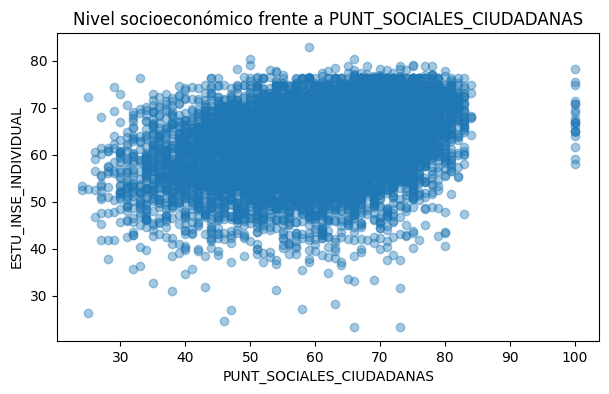

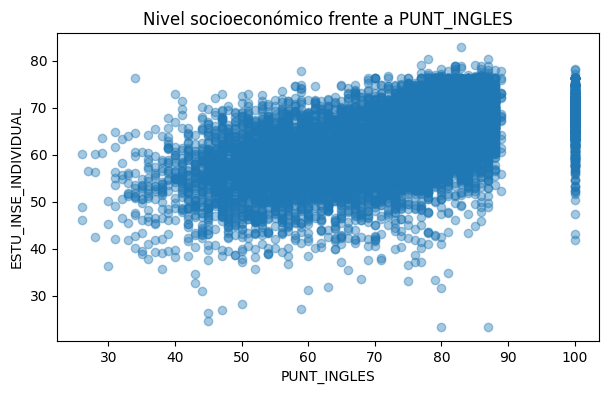

In [ ]:
import matplotlib.pyplot as plt

variables_explicativas = [
    'PUNT_LECTURA_CRITICA',
    'PUNT_MATEMATICAS',
    'PUNT_C_NATURALES',
    'PUNT_SOCIALES_CIUDADANAS',
    'PUNT_INGLES'
]

for variable in variables_explicativas:
    plt.figure(figsize=(7, 4))

    plt.scatter(
        icfes_sin_nan[variable],
        icfes_sin_nan['ESTU_INSE_INDIVIDUAL'],
        alpha=0.4
    )

    plt.xlabel(variable)
    plt.ylabel('ESTU_INSE_INDIVIDUAL')
    plt.title(f'Nivel socioeconómico frente a {variable}')
    plt.show()


#<h1><font color="#7D3C98">***Análisis del diagrama de dispersión: Lectura Crítica***</font></h1>

El diagrama de dispersión entre el puntaje de Lectura Crítica y el índice socioeconómico individual muestra una tendencia general positiva, aunque con una dispersión considerable de las observaciones. A medida que aumenta el puntaje en Lectura Crítica, se aprecia una tendencia a encontrar valores más elevados del índice socioeconómico. Sin embargo, esta relación no es uniforme, ya que para un mismo intervalo de puntajes se presentan estudiantes con diferentes valores del índice.

La mayor concentración de observaciones se encuentra aproximadamente entre los puntajes de Lectura Crítica de 40 y 75, y los valores del índice socioeconómico entre 50 y 75. Esta concentración indica que una proporción importante de los estudiantes se ubica en niveles intermedios y altos de ambas variables. No obstante, la nube presenta una amplitud vertical considerable, lo cual evidencia que los puntajes de Lectura Crítica no permiten determinar de manera precisa el nivel socioeconómico individual.

También se identifican observaciones alejadas de la región de mayor concentración, con valores del índice socioeconómico relativamente bajos incluso para puntajes moderados o altos en Lectura Crítica. Estas observaciones podrían corresponder a casos particulares que merecen revisión, aunque su presencia visual no permite clasificarlas automáticamente como errores o valores atípicos estadísticos.

Un aspecto relevante es la acumulación de observaciones cerca del puntaje 100. Esta concentración genera una columna vertical de puntos, lo que indica que varios estudiantes obtuvieron el mismo puntaje máximo o un valor ubicado en ese límite. Debido a esta acumulación, las diferencias individuales en el extremo superior de la escala no pueden apreciarse completamente mediante el gráfico.

Estos patrones son coherentes con el coeficiente de Pearson de 0,3548, el de Spearman de 0,3576 y el de Kendall de 0,2464, obtenidos previamente. Los tres coeficientes indican una asociación positiva de magnitud moderada o relativamente limitada, según la medida utilizada. La similitud entre Pearson y Spearman sugiere que la asociación lineal y la asociación monotónica presentan magnitudes parecidas en estos datos.

En conclusión, Lectura Crítica presenta una asociación positiva con el índice socioeconómico individual, pero la dispersión observada indica que su capacidad para explicar individualmente las diferencias socioeconómicas es limitada. Por ello, resulta pertinente estudiar esta variable junto con las demás pruebas mediante un modelo de regresión múltiple.

#<h1><font color="#7D3C98">***Análisis del diagrama de dispersión: Matemáticas***</font></h1>


El diagrama de dispersión entre Matemáticas y el índice socioeconómico individual presenta una tendencia general positiva. A medida que aumentan los puntajes de Matemáticas, los valores del índice socioeconómico tienden también a ubicarse en intervalos más altos. Esta configuración visual sugiere que ambas variables están asociadas, aunque no existe una correspondencia exacta entre los resultados académicos y el índice.

La mayor densidad de puntos se concentra aproximadamente entre los puntajes de Matemáticas de 40 y 80, y los valores del índice socioeconómico entre 50 y 75. La amplitud vertical de la nube muestra que estudiantes con resultados similares en Matemáticas pueden presentar diferencias apreciables en el índice socioeconómico. Por tanto, el puntaje de esta prueba no constituye por sí solo un indicador suficiente para estimar con precisión la situación socioeconómica individual.

En la región de puntajes altos se observa una concentración importante de observaciones, así como una acumulación en el valor 100. Esta última puede relacionarse con el límite superior de la escala de la prueba. La presencia de puntos alejados de la concentración principal también sugiere que existen observaciones con comportamientos diferentes al patrón predominante, las cuales podrían examinarse mediante análisis adicionales de residuos y valores atípicos.

Los coeficientes de correlación respaldan la tendencia observada. Matemáticas presenta un coeficiente de Pearson de 0,3767, Spearman de 0,3939 y Kendall de 0,2711. Entre las cinco pruebas analizadas, registra la segunda asociación más alta según Pearson y Spearman, después de Inglés. El hecho de que Spearman sea ligeramente superior a Pearson sugiere que la asociación basada en los rangos es algo más marcada que la asociación lineal, aunque la diferencia es pequeña y no demuestra por sí sola una relación no lineal.

Estos resultados indican que Matemáticas constituye una variable relevante para estudiar la relación entre desempeño académico e índice socioeconómico. Sin embargo, la correlación no debe confundirse con la contribución exclusiva de esta prueba en un modelo múltiple, pues parte de la información que contiene puede estar compartida con las demás áreas evaluadas.

En conclusión, Matemáticas presenta una asociación positiva relativamente marcada con el índice socioeconómico dentro del conjunto de variables estudiadas. La dispersión de los puntos y la concentración en determinados puntajes muestran, no obstante, que esta relación no es perfecta y que su capacidad explicativa debe evaluarse conjuntamente con las otras pruebas.

#<h1><font color="#7D3C98">***Análisis del diagrama de dispersión: Ciencias Naturales***</font></h1>


La representación gráfica de Ciencias Naturales frente al índice socioeconómico individual muestra una tendencia ascendente general, aunque menos definida que una relación lineal perfecta. Los valores del índice tienden a ser mayores en los intervalos superiores del puntaje, pero se mantiene una dispersión considerable de observaciones a lo largo de la distribución.

La nube de puntos se concentra principalmente en puntajes de Ciencias Naturales comprendidos aproximadamente entre 35 y 80, con valores del índice socioeconómico que se agrupan con mayor frecuencia entre 50 y 75. Esta distribución evidencia una región de alta densidad de estudiantes, pero también muestra una amplitud importante en los valores de la respuesta para niveles similares de desempeño.

Se observan, además, puntos con valores bajos del índice socioeconómico en distintos niveles de puntaje. Estos casos indican que un resultado académico determinado no se asocia necesariamente con un único valor del índice. No es posible atribuir estas diferencias a causas específicas a partir del gráfico, pues para ello se necesitaría incorporar otras variables y un diseño de análisis apropiado.

Al igual que en las demás pruebas, aparece una acumulación de observaciones en el puntaje 100. Este patrón debe interpretarse considerando que los puntajes se encuentran limitados por la escala de evaluación y que varios estudiantes pueden compartir el mismo resultado máximo. En consecuencia, la distribución de puntos no es completamente continua y presenta concentraciones que pueden influir en los indicadores de asociación.

Los coeficientes obtenidos fueron 0,3599 para Pearson, 0,3647 para Spearman y 0,2505 para Kendall. Estos valores muestran una asociación positiva de magnitud similar a la observada para Lectura Crítica y Sociales y Ciudadanas. La cercanía entre Pearson y Spearman indica que ambas medidas identifican una intensidad semejante de asociación en los datos analizados.

Sin embargo, en el análisis previo de regresión múltiple, la eliminación de Ciencias Naturales produjo una disminución de \(R^2\) que se redondeó a 0,0000. Esto no contradice la correlación positiva observada: la correlación mide la asociación entre Ciencias Naturales y el índice de manera individual, mientras que la comparación de \(R^2\) evalúa cuánto cambia el ajuste cuando se elimina esta variable después de incluir las demás pruebas. La información compartida entre los puntajes puede hacer que su contribución adicional sea muy pequeña.

En conclusión, Ciencias Naturales presenta una asociación positiva con el índice socioeconómico individual, pero su aporte específico al modelo múltiple debe distinguirse de su correlación individual. Esta diferencia demuestra la importancia de complementar la exploración gráfica con análisis multivariados.

#<h1><font color="#7D3C98">***Análisis del diagrama de dispersión: Sociales y Ciudadanas***</font></h1>


El diagrama de dispersión de Sociales y Ciudadanas frente al índice socioeconómico individual presenta una tendencia positiva general, acompañada de una dispersión amplia de los datos. La nube sugiere que los estudiantes con puntajes más elevados tienden a presentar valores superiores del índice socioeconómico, aunque existe una variabilidad importante para diferentes niveles de desempeño.

La mayor concentración de observaciones se ubica aproximadamente entre los puntajes de 40 y 80, mientras que el índice socioeconómico presenta una concentración más visible entre 50 y 75. Esta configuración muestra que una gran parte de los estudiantes se encuentra en una región intermedia o alta de ambas variables. Sin embargo, la extensión vertical de la nube evidencia que no existe una correspondencia única entre el puntaje de Sociales y Ciudadanas y el índice socioeconómico.

También se observan puntos alejados de la concentración central, incluidos valores bajos del índice para puntajes medios o altos. Estos casos contribuyen a la variabilidad general y pueden influir en los indicadores estadísticos, aunque no deben considerarse errores sin una verificación adicional. De igual manera, la distribución muestra una acumulación de observaciones en los puntajes altos, con una columna visible en 100, que puede estar asociada con el límite superior de la escala.

Los coeficientes de correlación fueron 0,3573 para Pearson, 0,3624 para Spearman y 0,2488 para Kendall. Las tres medidas indican una asociación positiva de magnitud parecida a la de Lectura Crítica y Ciencias Naturales. La pequeña diferencia entre Pearson y Spearman sugiere que la asociación monotónica y la lineal tienen magnitudes cercanas, aunque estas medidas responden a propiedades estadísticas diferentes.

En el análisis de regresión múltiple, al eliminar Sociales y Ciudadanas, la disminución de \(R^2\) también se redondeó a 0,0000. Esto significa que el cambio fue muy pequeño a la precisión reportada, no necesariamente que fuera exactamente cero. El resultado puede explicarse porque parte de la información de esta prueba se encuentra representada también en los demás puntajes incluidos en el modelo.

En conclusión, Sociales y Ciudadanas presenta una asociación positiva con el índice socioeconómico individual, pero su contribución adicional al ajuste del modelo múltiple parece reducida según los resultados redondeados. Este hallazgo muestra que una variable puede estar correlacionada individualmente con la respuesta y, al mismo tiempo, aportar poca información nueva cuando se consideran otros predictores relacionados.

#<h1><font color="#7D3C98">***Análisis del diagrama de dispersión: Inglés***</font></h1>

El diagrama de dispersión entre Inglés y el índice socioeconómico individual muestra una tendencia ascendente más marcada visualmente que la observada en las otras cuatro pruebas. A medida que aumentan los puntajes de Inglés, los valores del índice socioeconómico tienden a concentrarse en niveles más elevados. Aunque la relación no es perfecta y persiste una dispersión considerable, la nube presenta una organización ascendente reconocible.

La mayor concentración de observaciones se encuentra aproximadamente entre los puntajes de Inglés de 45 y 88 y los valores del índice socioeconómico entre 50 y 75. En los intervalos inferiores de Inglés se observa una mayor presencia de valores relativamente bajos del índice, mientras que en los intervalos superiores predominan con mayor frecuencia valores intermedios y altos. Este patrón es compatible con una asociación positiva entre ambas variables.

A pesar de esta tendencia, la dispersión vertical continúa siendo importante. Para puntajes de Inglés cercanos, por ejemplo, a 70 u 80, existen estudiantes con diferentes valores del índice socioeconómico. Por tanto, aunque Inglés parece presentar una relación más marcada con la respuesta, el puntaje de esta prueba no permite determinar de forma exacta el índice de cada estudiante.

Se aprecia una concentración de puntos en el valor 100, que forma una columna vertical en el extremo derecho del gráfico. Esta acumulación refleja que varios registros comparten el valor máximo del puntaje representado. Además de dificultar la visualización de observaciones superpuestas, esta concentración debe considerarse al interpretar la relación, dado que las diferencias entre estudiantes con resultados cercanos al máximo quedan parcialmente ocultas.

Los coeficientes de correlación confirman que Inglés presenta la asociación individual más alta con el índice socioeconómico entre las cinco pruebas. Se obtuvo un coeficiente de Pearson de 0,5512, uno de Spearman de 0,5657 y uno de Kendall de 0,3958. Los dos primeros indican una asociación positiva de magnitud moderada, superior a la registrada para las demás áreas. La cercanía entre Pearson y Spearman sugiere que la asociación lineal y la monotónica tienen magnitudes similares, mientras que el coeficiente de Kendall confirma una concordancia positiva entre los rangos de ambas variables.

Este resultado también es coherente con el análisis exploratorio del modelo múltiple: al retirar Inglés, el \(R^2\) disminuyó de 0,3060 a 0,1639, una reducción de 0,1421. Entre las variables evaluadas, esta fue la mayor disminución observada, lo que indica que Inglés aporta información importante para explicar el índice socioeconómico dentro del modelo considerado. Sin embargo, ni la correlación ni la reducción de \(R^2\) permiten afirmar que el desempeño en Inglés cause cambios en el nivel socioeconómico.

En conclusión, Inglés presenta la asociación individual más fuerte con el índice socioeconómico entre las cinco pruebas analizadas y constituye un predictor relevante dentro del modelo de regresión estudiado. Aun así, la dispersión de las observaciones y el carácter observacional de los datos exigen interpretar esta relación como una asociación estadística y no como una explicación causal.


In [ ]:
from scipy.stats import pearsonr, spearmanr, kendalltau

variable_respuesta = 'ESTU_INSE_INDIVIDUAL'

for variable in variables_explicativas:
    x = icfes_sin_nan[variable]
    y = icfes_sin_nan[variable_respuesta]

    pearson = pearsonr(x, y).statistic
    spearman = spearmanr(x, y).statistic
    kendall = kendalltau(x, y).statistic

    print(f"\nVariable: {variable}")
    print(f"Pearson:  {pearson:.4f}")
    print(f"Spearman: {spearman:.4f}")
    print(f"Kendall:  {kendall:.4f}")


Variable: PUNT_LECTURA_CRITICA
Pearson:  0.3548
Spearman: 0.3576
Kendall:  0.2464

Variable: PUNT_MATEMATICAS
Pearson:  0.3767
Spearman: 0.3939
Kendall:  0.2711

Variable: PUNT_C_NATURALES
Pearson:  0.3599
Spearman: 0.3647
Kendall:  0.2505

Variable: PUNT_SOCIALES_CIUDADANAS
Pearson:  0.3573
Spearman: 0.3624
Kendall:  0.2488

Variable: PUNT_INGLES
Pearson:  0.5512
Spearman: 0.5657
Kendall:  0.3958



#<h1><font color="#7D3C98">***Análisis e interpretación de los coeficientes de correlación***</font></h1>

Con el propósito de estudiar la asociación entre el nivel socioeconómico individual de los estudiantes (`ESTU_INSE_INDIVIDUAL`) y los puntajes obtenidos en las cinco pruebas Saber 11, se calcularon los coeficientes de correlación de Pearson, Spearman y Kendall. La utilización conjunta de estos indicadores permite examinar las relaciones desde perspectivas complementarias: Pearson mide la intensidad y dirección de la asociación lineal; Spearman evalúa la asociación monotónica a partir de los rangos de las observaciones; y Kendall cuantifica la concordancia entre pares de observaciones. Por tanto, la comparación de los tres coeficientes permite determinar si las conclusiones sobre la asociación entre las variables se mantienen al utilizar diferentes medidas estadísticas.

Los resultados muestran que los quince coeficientes calculados son positivos. Este comportamiento indica que, en términos generales, los estudiantes con mayores puntajes en las pruebas tienden a presentar valores más elevados de nivel socioeconómico individual. No obstante, la magnitud de los coeficientes varía entre las áreas evaluadas, lo que evidencia diferencias en la intensidad de la asociación observada.

La prueba de inglés presenta los coeficientes más altos en los tres métodos: 0,5512 para Pearson, 0,5657 para Spearman y 0,3958 para Kendall. Estos resultados la identifican como la variable con mayor asociación individual con el nivel socioeconómico dentro del conjunto analizado. La cercanía entre los coeficientes de Pearson y Spearman sugiere que la asociación observada no se limita a una relación lineal, sino que también se mantiene al considerar el orden relativo de los puntajes. Sin embargo, esta semejanza no demuestra por sí sola que la relación sea estrictamente lineal ni permite descartar posibles valores atípicos.

En segundo lugar se encuentra matemáticas, cuyos coeficientes fueron 0,3767, 0,3939 y 0,2711 para Pearson, Spearman y Kendall, respectivamente. Aunque esta variable presenta una asociación positiva con el nivel socioeconómico, su intensidad es inferior a la observada para inglés. Por su parte, lectura crítica, ciencias naturales y sociales y ciudadanas presentan coeficientes de Pearson de 0,3548, 0,3599 y 0,3573, respectivamente. La proximidad entre estos valores indica que las tres áreas tienen asociaciones lineales de magnitudes similares con la variable respuesta. Un comportamiento equivalente se observa en los coeficientes de Spearman y Kendall.

La comparación entre los métodos también aporta información relevante. En todas las variables, los coeficientes de Spearman son ligeramente superiores a los de Pearson, mientras que los coeficientes de Kendall presentan valores numéricamente inferiores. Esta diferencia no debe interpretarse como una contradicción entre los resultados, dado que cada medida utiliza un procedimiento distinto para cuantificar la asociación. En particular, los coeficientes de Spearman y Kendall se basan en rangos y concordancias, mientras que Pearson evalúa la asociación lineal en las escalas originales. Además, sus magnitudes no son directamente equivalentes, por lo que la comparación debe centrarse principalmente en el sentido de la asociación y en el orden relativo de las variables.

Desde la perspectiva de la selección preliminar de variables explicativas, los resultados sugieren priorizar el puntaje de inglés, seguido del puntaje de matemáticas. Las otras tres pruebas también presentan asociaciones positivas, por lo que no sería adecuado descartarlas únicamente a partir de sus correlaciones individuales. Una variable puede mostrar una asociación moderada por separado y, aun así, aportar información útil cuando se incorpora a un modelo que considera simultáneamente las demás variables.

Es importante señalar que los coeficientes de correlación no establecen relaciones causales ni permiten determinar, por sí solos, la capacidad predictiva de un modelo de regresión múltiple. Asimismo, aunque los resultados permiten comparar la magnitud de las asociaciones observadas, no se han calculado aquí intervalos de confianza ni pruebas de significación estadística para estos coeficientes. Por consiguiente, las conclusiones deben entenderse como una caracterización descriptiva de las relaciones presentes en la muestra analizada.

En síntesis, la prueba de inglés presenta la asociación individual más fuerte con el nivel socioeconómico, seguida por matemáticas, mientras que lectura crítica, ciencias naturales y sociales y ciudadanas muestran asociaciones positivas de magnitudes semejantes. Estos hallazgos constituyen una base estadística para el siguiente procedimiento de la actividad: comparar modelos de regresión lineal múltiple mediante el coeficiente de determinación \(R^2\), con el fin de evaluar el aporte de cada variable cuando las pruebas se consideran conjuntamente.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

y = icfes_sin_nan['ESTU_INSE_INDIVIDUAL']

# Modelo con las cinco variables explicativas
modelo_completo = LinearRegression()
modelo_completo.fit(icfes_sin_nan[variables_explicativas], y)

predicciones = modelo_completo.predict(
    icfes_sin_nan[variables_explicativas]
)

r2_completo = r2_score(y, predicciones)

print(f"R² del modelo completo: {r2_completo:.4f}")

# Modelos excluyendo una variable a la vez
for variable in variables_explicativas:
    variables_modelo = [
        v for v in variables_explicativas if v != variable
    ]

    modelo = LinearRegression()
    modelo.fit(icfes_sin_nan[variables_modelo], y)

    predicciones = modelo.predict(icfes_sin_nan[variables_modelo])
    r2 = r2_score(y, predicciones)

    print(f"R² sin {variable}: {r2:.4f}")
    print(f"Disminución de R²: {r2_completo - r2:.4f}")


R² del modelo completo: 0.3060
R² sin PUNT_LECTURA_CRITICA: 0.3056
Disminución de R²: 0.0004
R² sin PUNT_MATEMATICAS: 0.3043
Disminución de R²: 0.0017
R² sin PUNT_C_NATURALES: 0.3060
Disminución de R²: 0.0000
R² sin PUNT_SOCIALES_CIUDADANAS: 0.3060
Disminución de R²: 0.0000
R² sin PUNT_INGLES: 0.1639
Disminución de R²: 0.1421


#<h1><font color="#7D3C98">***Interpretación de los resultados***</font></h1>



El modelo de regresión lineal múltiple completo, construido con las cinco variables explicativas, obtuvo un coeficiente de determinación \(R^2=0.3060\). Esto significa que el modelo explica aproximadamente el 30,60 % de la variabilidad de la variable ESTU_INSE_INDIVIDUAL a partir de los puntajes de las cinco pruebas Saber 11 consideradas.

Al eliminar cada variable explicativa por separado, se observa que el puntaje de inglés es la variable cuya ausencia produce el mayor cambio en el ajuste del modelo. Cuando se excluye PUNT_INGLES, el \(R^2\) disminuye de 0.3060 a 0.1639, lo que representa una reducción de 0.1421. Esto indica que el puntaje de inglés aporta información importante para explicar la variabilidad del índice socioeconómico individual dentro del modelo analizado.

Por otra parte, al excluir matemáticas, el \(R^2\) disminuye en 0.0017, mientras que al excluir lectura crítica disminuye en 0.0004. Finalmente, al retirar ciencias naturales o sociales y ciudadanas, el valor de \(R^2\) se mantiene en 0.3060 cuando se redondea a cuatro decimales. Esto sugiere que, en presencia de las demás variables, su contribución individual al ajuste del modelo es muy pequeña.

En conclusión, inglés es la variable con mayor contribución individual al ajuste del modelo, seguida de matemáticas y lectura crítica, según la disminución del \(R^2\) observada al retirar cada predictor. Sin embargo, estos resultados no demuestran que las variables carezcan por completo de importancia: su aporte puede estar relacionado con la información compartida con los demás puntajes.

Es importante señalar que este análisis compara el ajuste de los modelos sobre los mismos datos utilizados para estimarlos. Por tanto, permite explorar la contribución de cada variable, pero no basta por sí solo para determinar cuál modelo tendrá mejor capacidad predictiva sobre datos nuevos.

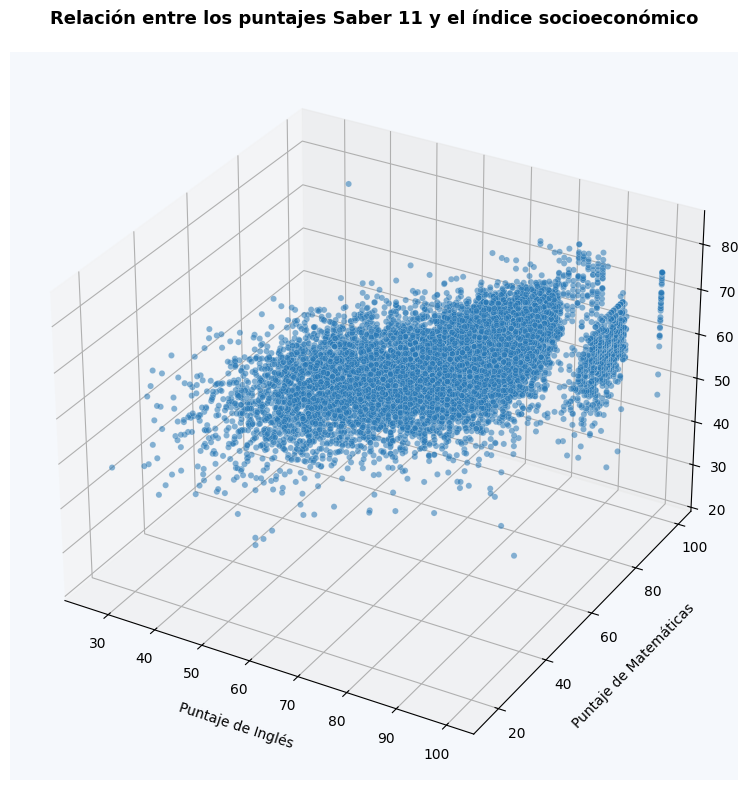

In [23]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    icfes_sin_nan['PUNT_INGLES'],
    icfes_sin_nan['PUNT_MATEMATICAS'],
    icfes_sin_nan['ESTU_INSE_INDIVIDUAL'],
    color='#2878B5',
    alpha=0.55,
    s=20,
    edgecolors='white',
    linewidths=0.2
)

ax.set_xlabel('Puntaje de Inglés', labelpad=10)
ax.set_ylabel('Puntaje de Matemáticas', labelpad=10)
ax.set_zlabel('Índice socioeconómico individual', labelpad=10)

ax.set_title(
    'Relación entre los puntajes Saber 11 y el índice socioeconómico',
    pad=20,
    fontsize=13,
    fontweight='bold'
)

ax.set_facecolor('#F5F8FC')
fig.patch.set_facecolor('white')

ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


#<h1><font color="#7D3C98">***Análisis e interpretación del diagrama de dispersión tridimensional***</font></h1>


El diagrama de dispersión tridimensional permite examinar conjuntamente la relación entre el puntaje obtenido en la prueba de Inglés, el puntaje de Matemáticas y el índice socioeconómico individual (`ESTU_INSE_INDIVIDUAL`) de los estudiantes evaluados en Saber 11. Cada punto representa un registro del conjunto de datos, ubicado según los valores observados en las tres variables. Esta representación facilita la identificación de tendencias generales, concentraciones de observaciones y posibles patrones que no se aprecian con la misma claridad al estudiar las variables de manera aislada.

En primer lugar, se observa una tendencia general ascendente del índice socioeconómico a medida que aumentan los puntajes de Inglés y Matemáticas. Esta configuración visual sugiere que los resultados más altos en ambas pruebas tienden a asociarse con valores más elevados del índice socioeconómico individual. Sin embargo, la tendencia no es perfectamente definida: para combinaciones similares de puntajes existen estudiantes con diferentes valores del índice. Por tanto, la relación observada es de carácter probabilístico y no constituye una regla que se cumpla para todas las observaciones.

En segundo lugar, la nube de puntos presenta una dispersión considerable alrededor de su tendencia general. Este comportamiento indica que los puntajes de Inglés y Matemáticas, aunque contienen información asociada con el índice socioeconómico, no permiten determinarlo con exactitud. La variabilidad restante podría estar relacionada con otros factores no incluidos en esta representación, así como con la variabilidad propia de los datos. No obstante, el gráfico por sí solo no permite identificar ni cuantificar la influencia de esos posibles factores.

También se aprecia una concentración de observaciones en los valores altos de los puntajes, particularmente cerca de 100. Esta acumulación puede reflejar la naturaleza acotada de las escalas de las pruebas y la presencia de numerosos estudiantes con resultados elevados. La concentración en los límites superiores puede dificultar la identificación visual de diferencias entre estudiantes con puntajes cercanos y afectar la forma de la relación observada. Por esta razón, conviene interpretar la nube completa y evitar conclusiones basadas únicamente en los grupos de puntos más densos.

Desde la perspectiva de la regresión múltiple, el diagrama proporciona una exploración visual de la asociación conjunta entre dos variables explicativas y la variable respuesta. Sin embargo, no permite establecer por sí solo cuál de los dos puntajes tiene mayor capacidad explicativa, ya que ambas variables pueden compartir información estadística. Para examinar su contribución individual y conjunta es necesario considerar los resultados de los modelos de regresión y sus indicadores de ajuste.

En conclusión, la representación gráfica evidencia una asociación positiva general entre los puntajes de Inglés y Matemáticas y el índice socioeconómico individual, acompañada de una dispersión importante y de concentraciones de observaciones en puntajes altos. Estos resultados respaldan la pertinencia de estudiar las variables mediante modelos de regresión, pero no demuestran una relación causal. La capacidad de predicción de los modelos deberá evaluarse posteriormente con datos de prueba que no hayan sido utilizados durante el entrenamiento.

In [ ]:
from sklearn.model_selection import train_test_split

# Definir las variables explicativas y la variable respuesta
X = icfes_sin_nan[variables_explicativas]
y = icfes_sin_nan['ESTU_INSE_INDIVIDUAL']

# Dividir los datos: 80 % entrenamiento y 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Verificar las dimensiones de los conjuntos
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)
print("Observaciones para entrenamiento:", len(y_train))
print("Observaciones para prueba:", len(y_test))

Datos de entrenamiento: (9482, 5)
Datos de prueba: (2371, 5)
Observaciones para entrenamiento: 9482
Observaciones para prueba: 2371


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Crear el modelo de regresión lineal múltiple
modelo_lineal = LinearRegression()

# Entrenar el modelo con el 80 % de los datos
modelo_lineal.fit(X_train, y_train)

# Predecir el índice socioeconómico con los datos de prueba
y_pred_lineal = modelo_lineal.predict(X_test)

# Evaluar el modelo
r2_lineal = r2_score(y_test, y_pred_lineal)
mae_lineal = mean_absolute_error(y_test, y_pred_lineal)
rmse_lineal = np.sqrt(mean_squared_error(y_test, y_pred_lineal))

print("Resultados del modelo de regresión lineal múltiple")
print(f"R² en prueba: {r2_lineal:.4f}")
print(f"Error absoluto medio (MAE): {mae_lineal:.4f}")
print(f"Raíz del error cuadrático medio (RMSE): {rmse_lineal:.4f}")

print("\nIntercepto:", modelo_lineal.intercept_)

print("\nCoeficientes del modelo:")
for variable, coeficiente in zip(X_train.columns, modelo_lineal.coef_):
    print(f"{variable}: {coeficiente:.4f}")

Resultados del modelo de regresión lineal múltiple
R² en prueba: 0.3198
Error absoluto medio (MAE): 4.8011
Raíz del error cuadrático medio (RMSE): 6.1236

Intercepto: 41.618440410307116

Coeficientes del modelo:
PUNT_LECTURA_CRITICA: -0.0305
PUNT_MATEMATICAS: 0.0459
PUNT_C_NATURALES: -0.0058
PUNT_SOCIALES_CIUDADANAS: 0.0056
PUNT_INGLES: 0.2801



#<h1><font color="#7D3C98">***Análisis del modelo de regresión lineal múltiple***</font></h1>
El modelo de regresión lineal múltiple se construyó utilizando como variable respuesta el índice socioeconómico individual (`ESTU_INSE_INDIVIDUAL`) y como variables explicativas los puntajes de Lectura Crítica, Matemáticas, Ciencias Naturales, Sociales y Ciudadanas e Inglés. Para evaluar su capacidad predictiva, se utilizaron 9.482 observaciones para el entrenamiento y 2.371 para la prueba, correspondientes al 80 % y al 20 % de los datos completos, respectivamente.

El coeficiente de determinación obtenido en el conjunto de prueba fue \(R^2=0.3198\). Esto significa que las predicciones del modelo explican aproximadamente el 31,98 % de la variabilidad observada del índice socioeconómico individual en los datos de prueba, respecto de la predicción basada en la media de esa variable. El porcentaje restante, cercano al 68,02 %, no queda explicado por el modelo en esta evaluación. Por tanto, aunque existe capacidad predictiva, el ajuste es moderado y los cinco puntajes no son suficientes para representar toda la variabilidad del índice socioeconómico.

El error absoluto medio (MAE) fue de 4,8011. En términos prácticos, las predicciones se apartan de los valores observados aproximadamente 4,80 unidades en promedio, considerando la magnitud absoluta de los errores. Por su parte, la raíz del error cuadrático medio (RMSE) fue de 6,1236. Este indicador también mide el error en las mismas unidades del índice, pero penaliza con mayor intensidad los errores de mayor magnitud. El hecho de que el RMSE sea superior al MAE sugiere que algunos errores grandes elevan el promedio cuadrático, aunque esta diferencia por sí sola no permite establecer cuántas observaciones presentan errores elevados.

El intercepto estimado fue de 41,6184. En la ecuación del modelo, este valor corresponde a la predicción del índice socioeconómico cuando todos los puntajes explicativos son iguales a cero. Sin embargo, dado que esa combinación de puntajes puede no ser representativa de la población estudiada, el intercepto tiene principalmente una función matemática dentro de la ecuación y no debe interpretarse automáticamente como un perfil real de estudiante.

La ecuación estimada del modelo es:

\[
\begin{aligned}
\widehat{\text{INSE}}={}&41.6184
-0.0305(\text{Lectura Crítica})\\
&+0.0459(\text{Matemáticas})\\
&-0.0058(\text{Ciencias Naturales})\\
&+0.0056(\text{Sociales y Ciudadanas})\\
&+0.2801(\text{Inglés}).
\end{aligned}
\]

Los coeficientes representan el cambio esperado en la predicción del índice socioeconómico asociado con un aumento de una unidad en el puntaje correspondiente, manteniendo constantes los otros cuatro puntajes.

El coeficiente de Inglés fue positivo y alcanzó 0,2801. Por tanto, manteniendo constantes las demás variables, un aumento de un punto en Inglés se asocia con un incremento estimado de 0,2801 unidades en el índice socioeconómico. Este fue el coeficiente positivo de mayor magnitud entre los estimados, lo que coincide con el análisis previo de correlaciones, en el que Inglés presentó la asociación bivariada más alta con la variable respuesta.

Matemáticas también presentó un coeficiente positivo, de 0,0459. Esto indica que, manteniendo constantes los demás puntajes, un aumento de un punto en esta prueba se relaciona con un incremento estimado de 0,0459 unidades en el índice. En comparación con Inglés, su coeficiente es menor en la escala original de las variables. Sin embargo, la magnitud de los coeficientes no debe utilizarse como única medida de importancia, pues los puntajes pueden presentar distribuciones y relaciones diferentes entre sí.

Los coeficientes de Lectura Crítica y Ciencias Naturales fueron negativos, con valores de -0,0305 y -0,0058, respectivamente. Esto significa que, una vez controlados estadísticamente los otros puntajes, el modelo estima una asociación condicional negativa para estas variables. Este resultado no implica que obtener mejores resultados en dichas pruebas cause una disminución del índice socioeconómico. Puede estar relacionado con la asociación entre los propios puntajes, dado que las cinco pruebas pueden compartir información estadística. Por ello, estos coeficientes deben interpretarse en el contexto del modelo múltiple y no como relaciones aisladas.

Por último, Sociales y Ciudadanas presentó un coeficiente positivo de 0,0056, de magnitud pequeña en la escala original. Esto indica una contribución marginal reducida a la predicción, una vez consideradas las otras cuatro pruebas. No obstante, para establecer si cada coeficiente es estadísticamente diferente de cero sería necesario estudiar sus errores estándar, intervalos de confianza o pruebas de significancia, aspectos que no se han calculado en esta etapa.

En conclusión, el modelo de regresión lineal múltiple presenta una capacidad predictiva moderada en los datos de prueba, con un \(R^2\) de 0,3198 y un error absoluto medio de aproximadamente 4,80 unidades. Inglés muestra la asociación condicional positiva de mayor magnitud entre los coeficientes estimados, mientras que los coeficientes negativos de algunas pruebas advierten que las relaciones dentro del modelo múltiple no necesariamente coinciden con las correlaciones individuales. Estos resultados proporcionan una referencia para comparar el desempeño de la red neuronal, que será evaluada con el mismo conjunto de prueba.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Escalar la variable respuesta utilizando solo los datos de entrenamiento
escalador_y = StandardScaler()
y_train_escalado = escalador_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Crear la red neuronal
modelo_red = Pipeline([
    ('escalador_X', StandardScaler()),
    ('red', MLPRegressor(
        hidden_layer_sizes=(100, 100, 100, 100, 100, 100),
        max_iter=500,
        activation='relu',
        solver='adam',
        learning_rate='invscaling',
        random_state=42
    ))
])

# Entrenar la red neuronal
modelo_red.fit(X_train, y_train_escalado)

# Realizar predicciones con los datos de prueba
predicciones_escaladas = modelo_red.predict(X_test)

# Convertir las predicciones a la escala original del índice
y_pred_red = escalador_y.inverse_transform(
    predicciones_escaladas.reshape(-1, 1)
).ravel()

# Evaluar el modelo
r2_red = r2_score(y_test, y_pred_red)
mae_red = mean_absolute_error(y_test, y_pred_red)
rmse_red = np.sqrt(mean_squared_error(y_test, y_pred_red))

print("Resultados de la red neuronal")
print(f"R² en prueba: {r2_red:.4f}")
print(f"Error absoluto medio (MAE): {mae_red:.4f}")
print(f"Raíz del error cuadrático medio (RMSE): {rmse_red:.4f}")

Resultados de la red neuronal
R² en prueba: -0.1275
Error absoluto medio (MAE): 6.1360
Raíz del error cuadrático medio (RMSE): 7.8840



#<h1><font color="#7D3C98">***Análisis del modelo de red neuronal***</font></h1>

La red neuronal de percepción multicapa (MLPRegressor) se entrenó utilizando seis capas ocultas, cada una con 100 neuronas, una función de activación ReLU y el optimizador Adam, de acuerdo con los parámetros establecidos para el ejercicio. Para evaluar su capacidad predictiva, se utilizaron las mismas observaciones de prueba empleadas en el modelo de regresión lineal múltiple, lo que permite comparar ambos métodos bajo las mismas condiciones.

El coeficiente de determinación obtenido en el conjunto de prueba fue \(R^2=-0.1275\). Este resultado es especialmente relevante, ya que un coeficiente de determinación negativo indica que las predicciones de la red neuronal fueron peores, en términos de error cuadrático, que utilizar la media de los valores observados en el conjunto de prueba como predicción para todos los estudiantes. Por consiguiente, con la configuración utilizada, la red neuronal no logró representar adecuadamente la variabilidad del índice socioeconómico individual en los datos que no participaron en el entrenamiento.

El error absoluto medio (MAE) fue de 6,1360. Esto significa que las predicciones se apartaron de los valores reales aproximadamente 6,14 unidades en promedio, considerando la magnitud absoluta de los errores. Por su parte, la raíz del error cuadrático medio (RMSE) alcanzó 7,8840. Como este indicador penaliza con mayor intensidad los errores de mayor magnitud, su valor superior al MAE sugiere que los errores grandes contribuyeron de manera importante al error global del modelo.

Una posible explicación de este desempeño es la complejidad de la arquitectura neuronal utilizada. La red cuenta con seis capas ocultas de 100 neuronas cada una, por lo que dispone de una gran cantidad de parámetros que deben estimarse durante el entrenamiento. Esta complejidad puede dificultar el aprendizaje de patrones que se generalicen a datos nuevos, especialmente si no se ajustan adecuadamente los hiperparámetros. No obstante, los indicadores obtenidos no permiten afirmar por sí solos que se haya producido sobreajuste; para confirmarlo sería necesario comparar el desempeño en entrenamiento y prueba.

También es importante considerar que el modelo se entrenó después de estandarizar las variables explicativas y la variable respuesta, y que las predicciones se transformaron nuevamente a la escala original antes de calcular los indicadores. De esta manera, el MAE y el RMSE pueden interpretarse en las unidades originales del índice socioeconómico.

En conclusión, la red neuronal, con los parámetros establecidos, presentó un desempeño predictivo insatisfactorio en el conjunto de prueba. Su \(R^2\) negativo y sus errores superiores a los obtenidos mediante regresión lineal indican que, en esta ejecución, no consiguió generalizar adecuadamente las relaciones presentes en los datos. Este resultado muestra que una arquitectura más compleja no garantiza mejores predicciones y que el desempeño de los modelos depende tanto de su estructura como de la configuración del entrenamiento y de las características de los datos.

In [15]:
# Identificar registros cuyo índice socioeconómico está vacío
# pero que tienen completos los cinco puntajes de las pruebas

variables_explicativas = [
    'PUNT_LECTURA_CRITICA',
    'PUNT_MATEMATICAS',
    'PUNT_C_NATURALES',
    'PUNT_SOCIALES_CIUDADANAS',
    'PUNT_INGLES'
]

variable_respuesta = 'ESTU_INSE_INDIVIDUAL'

datos_imputar = datos_icfes[
    datos_icfes[variable_respuesta].isna() &
    datos_icfes[variables_explicativas].notna().all(axis=1)
].copy()

print("Registros con índice faltante y cinco puntajes disponibles:",
      len(datos_imputar))

Registros con índice faltante y cinco puntajes disponibles: 849


In [16]:
# Seleccionar los cinco puntajes de los registros por imputar
X_imputar = datos_imputar[variables_explicativas]

# Estimar los valores faltantes con el modelo de regresión lineal
valores_imputados = modelo_lineal.predict(X_imputar)

# Crear una copia del conjunto de datos original
datos_icfes_imputados = datos_icfes.copy()

# Identificar las filas que cumplen las condiciones de imputación
mascara_imputacion = (
    datos_icfes_imputados[variable_respuesta].isna() &
    datos_icfes_imputados[variables_explicativas].notna().all(axis=1)
)

# Reemplazar únicamente los valores faltantes identificados
datos_icfes_imputados.loc[
    mascara_imputacion, variable_respuesta
] = valores_imputados

print("Registros imputados:", mascara_imputacion.sum())
print(
    "Valores faltantes antes:",
    datos_icfes[variable_respuesta].isna().sum()
)
print(
    "Valores faltantes después:",
    datos_icfes_imputados[variable_respuesta].isna().sum()
)

Registros imputados: 849
Valores faltantes antes: 849
Valores faltantes después: 0



#<h1><font color="#7D3C98">***Análisis de la imputación de valores faltantes***</font></h1>
La imputación se realizó sobre la variable `ESTU_INSE_INDIVIDUAL`, correspondiente al índice socioeconómico individual. Inicialmente, se identificaron 849 registros que presentaban valores faltantes en esta variable, pero que contaban con información completa en las cinco variables explicativas: Lectura Crítica, Matemáticas, Ciencias Naturales, Sociales y Ciudadanas e Inglés.

Para estimar los valores faltantes se utilizó el modelo de regresión lineal múltiple previamente entrenado con el 80 % de los datos completos. Esta decisión se fundamentó en su desempeño en el conjunto de prueba, donde obtuvo un coeficiente de determinación de 0,3198, un error absoluto medio de 4,8011 y una raíz del error cuadrático medio de 6,1236. En comparación con la red neuronal evaluada, la regresión lineal presentó mejores resultados predictivos.

El procedimiento permitió imputar los 849 registros identificados. El número de valores faltantes de la variable respuesta pasó de 849 a cero dentro del conjunto de datos imputado. Para conservar la información original, las estimaciones se incorporaron en una copia del conjunto de datos, denominada `datos_icfes_imputados`, sin modificar el conjunto inicial.

Desde el punto de vista estadístico, es importante distinguir entre los valores observados y los valores imputados. Los primeros corresponden a la información disponible en el conjunto de datos original, mientras que los segundos son estimaciones calculadas por el modelo. Por esta razón, la ausencia de valores faltantes después del procedimiento no significa que se hayan recuperado los valores reales desconocidos, sino que estos fueron sustituidos por predicciones.

Asimismo, dado que el modelo presentó una capacidad explicativa moderada en los datos de prueba, las estimaciones pueden contener errores considerables. La imputación permite disponer de un conjunto de datos más completo para determinados análisis posteriores, pero debe reconocerse la incertidumbre asociada con los valores estimados. Además, el procedimiento no garantiza que la distribución de la variable imputada sea idéntica a la distribución de los valores originalmente observados.

En conclusión, la regresión lineal múltiple permitió completar los 849 registros que tenían el índice socioeconómico faltante y disponían de los cinco puntajes requeridos. El procedimiento fue satisfactorio en términos de completar los datos identificados; sin embargo, la calidad de las estimaciones depende de la capacidad predictiva del modelo y debe tenerse en cuenta al interpretar los resultados posteriores.

In [17]:
import pandas as pd

# Perfiles hipotéticos de estudiantes
perfiles = pd.DataFrame({
    'PUNT_LECTURA_CRITICA': [90, 70],
    'PUNT_MATEMATICAS': [80, 95],
    'PUNT_C_NATURALES': [80, 90],
    'PUNT_SOCIALES_CIUDADANAS': [80, 80],
    'PUNT_INGLES': [40, 40]
}, index=['Perfil A: lectura alta', 'Perfil B: matemáticas altas'])

# Predecir el índice socioeconómico con la regresión lineal
perfiles['INSE_estimado'] = modelo_lineal.predict(
    perfiles[variables_explicativas]
)

# Calcular los puntajes ponderados de admisión
perfiles['Matematicas_UIS'] = (
    0.50 * perfiles['PUNT_MATEMATICAS']
    + 0.20 * perfiles['PUNT_LECTURA_CRITICA']
    + 0.10 * perfiles['PUNT_C_NATURALES']
    + 0.10 * perfiles['PUNT_SOCIALES_CIUDADANAS']
    + 0.10 * perfiles['PUNT_INGLES']
)

perfiles['Lic_Matematicas_UIS'] = perfiles['Matematicas_UIS']

perfiles['Medicina_UIS'] = (
    0.30 * perfiles['PUNT_C_NATURALES']
    + 0.25 * perfiles['PUNT_LECTURA_CRITICA']
    + 0.20 * perfiles['PUNT_MATEMATICAS']
    + 0.15 * perfiles['PUNT_SOCIALES_CIUDADANAS']
    + 0.10 * perfiles['PUNT_INGLES']
)

perfiles['Sistemas_UIS'] = (
    0.25 * perfiles['PUNT_C_NATURALES']
    + 0.20 * perfiles['PUNT_LECTURA_CRITICA']
    + 0.35 * perfiles['PUNT_MATEMATICAS']
    + 0.10 * perfiles['PUNT_SOCIALES_CIUDADANAS']
    + 0.10 * perfiles['PUNT_INGLES']
)

display(perfiles.round(2))

,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,INSE_estimado,Matematicas_UIS,Lic_Matematicas_UIS,Medicina_UIS,Sistemas_UIS
Perfil A: lectura alta,90,80,80,80,40,53.74,78.0,78.0,78.5,78.00
Perfil B: matemáticas altas,70,95,90,80,40,54.98,82.5,82.5,79.5,81.75



#<h1><font color="#7D3C98">***Análisis de los perfiles hipotéticos y de los puntajes ponderados de admisión***</font></h1>

Con el propósito de explorar posibles aplicaciones de los modelos construidos, se definieron dos perfiles hipotéticos de estudiantes a partir de sus puntajes en las pruebas Saber 11. Para cada perfil se estimó el índice socioeconómico individual mediante el modelo de regresión lineal múltiple y se calcularon los puntajes ponderados correspondientes a Matemáticas, Licenciatura en Matemáticas, Medicina e Ingeniería de Sistemas, utilizando las ponderaciones consideradas para cada programa académico.

El perfil A presenta un puntaje de 90 en Lectura Crítica, 80 en Matemáticas, Ciencias Naturales y Sociales y Ciudadanas, y 40 en Inglés. El modelo estimó para este perfil un índice socioeconómico de 53,74. En cuanto a los puntajes ponderados, obtuvo 78,00 para Matemáticas, 78,00 para Licenciatura en Matemáticas, 78,50 para Medicina y 78,00 para Ingeniería de Sistemas. Se observa que, aunque el perfil presenta un resultado alto en Lectura Crítica, su puntaje ponderado varía según la importancia asignada a cada prueba en el programa académico.

El perfil B presenta un puntaje de 70 en Lectura Crítica, 95 en Matemáticas, 90 en Ciencias Naturales, 80 en Sociales y Ciudadanas y 40 en Inglés. Para este perfil, el índice socioeconómico estimado fue de 54,98. Sus puntajes ponderados fueron 82,50 para Matemáticas, 82,50 para Licenciatura en Matemáticas, 79,50 para Medicina y 81,75 para Ingeniería de Sistemas.

Al comparar ambos perfiles, se observa que el perfil B obtiene mayores puntajes ponderados en Matemáticas, Licenciatura en Matemáticas e Ingeniería de Sistemas. Esto se relaciona con su mayor resultado en Matemáticas y Ciencias Naturales, áreas que tienen una participación importante en las ponderaciones de estos programas. En Medicina, el perfil B también supera al perfil A, aunque la diferencia es menor. En este programa, Ciencias Naturales tiene el mayor peso entre las pruebas consideradas, seguida de Lectura Crítica y Matemáticas.

Los resultados también permiten observar que Matemáticas y Licenciatura en Matemáticas presentan el mismo puntaje ponderado para cada perfil, debido a que en el cálculo se utilizaron las mismas ponderaciones para ambos programas. Esto no significa que sus procesos de admisión sean necesariamente idénticos en todos los aspectos, sino que la fórmula utilizada en este ejercicio produce el mismo resultado para los perfiles evaluados.

En relación con el índice socioeconómico, el perfil B presenta una estimación de 54,98, mientras que para el perfil A se obtuvo 53,74. La diferencia es de 1,24 unidades. Esta diferencia corresponde a la predicción del modelo a partir de los cinco puntajes considerados y no debe interpretarse como una medida directa del nivel de ingresos, de las condiciones familiares ni de las oportunidades educativas de los estudiantes.

Es fundamental señalar que los perfiles utilizados son hipotéticos y que los resultados no permiten afirmar que alguno de ellos sería admitido en la UIS. Para determinar si los puntajes ponderados son competitivos, es necesario compararlos con los puntajes de corte oficiales del programa y del periodo de admisión correspondiente. Ademáhass, el índice socioeconómico estimado y el puntaje ponderado de admisión son medidas diferentes, por lo que no deben confundirse.

En conclusión, el ejercicio muestra cómo la ponderación de las pruebas modifica el resultado de admisión según el programa académico y cómo un modelo de regresión puede utilizarse para estimar el índice socioeconómico a partir de los puntajes Saber 11. Sin embargo, las predicciones deben interpretarse con cautela, dado que el modelo presentó una capacidad predictiva moderada y los perfiles analizados no corresponden a estudiantes reales. La comparación con los puntajes de corte oficiales será necesaria para contextualizar adecuadamente los resultados.


La comparación de los perfiles hipotéticos con los rangos históricos de corte de la UIS permite contextualizar los puntajes ponderados obtenidos para los cuatro programas académicos seleccionados. Los perfiles presentan resultados comparativamente favorables para Matemáticas, Licenciatura en Matemáticas e Ingeniería de Sistemas, mientras que sus puntajes para Medicina se encuentran por debajo del límite inferior del rango histórico consultado.

El perfil B presenta mejores resultados ponderados que el perfil A en los cuatro programas, debido principalmente a sus mayores puntajes en Matemáticas y Ciencias Naturales. Esta diferencia evidencia la importancia de considerar las ponderaciones específicas de cada carrera al analizar los resultados de las pruebas Saber 11.

Por otra parte, el índice socioeconómico estimado fue de 53,74 para el perfil A y 54,98 para el perfil B. Aunque el segundo perfil presenta una estimación ligeramente superior, esta diferencia no debe interpretarse como evidencia de que un mayor puntaje académico cause un incremento del nivel socioeconómico. El modelo únicamente estima una asociación estadística a partir de las variables incluidas.

En conjunto, el ejercicio demuestra cómo los modelos de regresión pueden emplearse para explorar relaciones entre variables y realizar estimaciones, mientras que los puntajes ponderados permiten comparar perfiles académicos con referencias de admisión. Sin embargo, son procedimientos distintos: la regresión utilizada predice el índice socioeconómico individual, no la probabilidad de admisión. Además, los perfiles son hipotéticos y los cortes históricos no garantizan los resultados de futuros procesos de selección.

Por tanto, las conclusiones deben entenderse como un ejercicio de análisis estadístico y comparación de escenarios, no como una predicción definitiva sobre la admisión de estudiantes reales.

#<h1><font color="#7D3C98">***Conclusiones***</font></h1>
1. Las variables analizadas presentan asociaciones positivas con el índice socioeconómico individual. Los diagramas de dispersión mostraron tendencias generales crecientes, aunque también se observó una considerable dispersión de los datos. Esto indica que los puntajes académicos se relacionan con el índice socioeconómico, pero no permiten explicarlo por completo.

2. El puntaje de inglés presentó la asociación más fuerte con el índice socioeconómico. En el análisis de correlaciones obtuvo un coeficiente de Pearson de 0,5512, de Spearman de 0,5657 y de Kendall de 0,3958. Además, al excluir esta variable del modelo de regresión múltiple, el \(R^2\) disminuyó de 0,3060 a 0,1639. Estos resultados muestran que inglés fue la variable con mayor aporte individual a la capacidad explicativa del modelo evaluado, sin que esto implique una relación causal.

3. La regresión lineal múltiple obtuvo mejores resultados predictivos que la red neuronal evaluada. En el conjunto de prueba, la regresión lineal alcanzó un \(R^2\) de 0,3198, un error absoluto medio (MAE) de 4,8011 y una raíz del error cuadrático medio (RMSE) de 6,1236. En cambio, la red neuronal obtuvo un \(R^2\) de -0,1275, un MAE de 6,1360 y un RMSE de 7,8840. Por tanto, para esta partición de los datos y con la configuración utilizada, la regresión lineal presentó un desempeño superior.

4. La imputación permitió completar 849 registros con valores faltantes en el índice socioeconómico. Para ello se utilizó la regresión lineal múltiple, seleccionada por su mejor desempeño comparativo. Sin embargo, los valores imputados corresponden a estimaciones del modelo y no a valores reales recuperados. Por esta razón, deben interpretarse con precaución, considerando los errores de predicción y la capacidad explicativa moderada del modelo.

5. El análisis de perfiles académicos permitió explorar posibles escenarios de desempeño. Los puntajes ponderados calculados para los programas de Matemáticas, Licenciatura en Matemáticas, Medicina e Ingeniería de Sistemas facilitaron la comparación entre perfiles hipotéticos. No obstante, estos resultados solo pueden interpretarse como ejercicios exploratorios: para establecer posibilidades reales de admisión es necesario verificar las ponderaciones y los criterios oficiales de selección de la Universidad Industrial de Santander para el periodo correspondiente.

En conclusión, el trabajo permitió aplicar diferentes técnicas estadísticas y computacionales para estudiar la relación entre los puntajes Saber 11 y el índice socioeconómico individual. Los resultados muestran que, aunque las variables académicas contienen información útil para realizar estimaciones, su capacidad explicativa es limitada y existen diferencias importantes entre los modelos evaluados. Por ello, las predicciones deben utilizarse como aproximaciones y no como explicaciones definitivas del contexto socioeconómico de los estudiantes.



#<h1><font color="#7D3C98">***Bibliografía***</font></h1>


Universidad Industrial de Santander. (s. f.). *Criterios de selección de programas de pregrado*. Dirección de Admisión y Registro Académico. https://inscripciones.uis.edu.co/criterios-seleccion-pregrado/

